# Lab 1 - K-Nearest Neighbours

This lab is about the implementation and analysis of the KNN algorithm for classification problems

In [2]:
## If you use colab uncomment these lines to upload Material.zip , advance non neccessario per la consegna del report , facoltativo
from google.colab import files
files.upload()
!unzip Material.zip

Saving Material.zip to Material.zip
Archive:  Material.zip
   creating: Material/
   creating: Material/Classification/
  inflating: Material/Classification/Test1.dat  
  inflating: Material/Classification/Test2.dat  
  inflating: Material/Classification/Test3.dat  
  inflating: Material/Classification/Test4.dat  
  inflating: Material/Classification/Training3.dat  
  inflating: Material/Classification/Training4.dat  
  inflating: Material/Classification/Training1.dat  
  inflating: Material/Classification/Training2.dat  


In [11]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pickle
%matplotlib inline

### Data generation for binary classification

We start generating a training set for binary classification problems. Consider the following function, that generates random 2D points on the plane and assigns them a binary label according to their position w.r.t. a linear separator.

The function `linearBinaryClass`, given a sample size `n`, lower and upper bounds `low_D, high_D` for the domain of the samples and the linear function parameters `m, q`, generates a binary classification dataset i.e. it returns `X` and `Y`.

The signature of the function is the following:

`X, Y = linearBinaryClass(n, low_D, high_D, m, q)`

where
- **n** is the number of samples to be generated
- **low_D** and **high_D** are, respectively, the lower and upper bounds for the domain of the samples i.e.
$$X_{i,j} \sim \mathcal{U}(\text{low_D}, \text{high_D})$$
- **m, q** are the linear function parameters
- **X**, **Y**: 2-dimensional samples (X) associated with 1-dimensional binary labels (Y)


In [2]:
def linearBinaryClass(n, low_D, high_D, m, q):
    X = (np.random.rand(n, 2) * (high_D - low_D)) + low_D
    Y = np.sign((X[:,1] - (m * X[:,0]) + q))
    Y[Y==0] = 1
    return X,Y

In [ ]:
# **ADVANCED**
# always use random generators to get reproducible builds!
#
# 1. Create a random generator to get reproducible builds
# rng = np.random.default_rng()
#
# 2. Redefine the function linearBinaryClass (call it newlinearBinaryClass) using the generator in step 1., that is
def newlinearBinaryClass(n, low_D, high_D, m, q):
  rng = np.random.default_rng()
  X = (rng.random((n, 2)) * (high_D - low_D)) + low_D
  Y = np.sign((X[:,1] - (m * X[:,0]) + q))
  Y[Y==0] = 1
  return X,Y

### Computing the distance between input points

In order to build the KNN estimator we need to resort to a distance function.

Consider a function that computes the euclidean distance between two points...

In [3]:
def euclidDistance(P1,P2):
    return np.linalg.norm(P1-P2,2)

... and then a function that computes all the distance between two set of points stored in two matrices.

In [4]:
def allDistances(X1, X2):
    D = np.zeros((X1.shape[0], X2.shape[0]))
    for idx1 in range(len(X1)):
        for idx2 in range(len(X2)):
            D[idx1,idx2] = euclidDistance(X1[idx1,:],X2[idx2,:])
    return D

The usage is the following:

`D = allDistances(X1,X2)`

where
- **X1** is a matrix of size $n_1 \times D$, where each row is a D-dimensional point
- **X2** is a matrix of size $n_2 \times D$, where each row is a D-dimensional point
- **D** is a matrix of size $n_1 \times n_2$, where each element `D[i,j]` is the distance between points (`X1[i, :]`, `X2[j, :]`)

In [ ]:
#  **ADVANCED**
# Python loops are slow! try to avoid them where possible!
#
# Define a new function Fast_AllDistances that computes all the dinstances without using loops
#
def Fast_AllDistances(X1, X2):
   X1_sqnorm = np.sum(X1**2, axis=1, keepdims=True)
   X2_sqnorm = np.sum(X2**2, axis=1, keepdims=True)
#     adv. lesson 2: prove it!
   D_sq = X1_sqnorm + X2_sqnorm.T - 2 * X1 @ X2.T
#     adv. lesson 3: ensure numerical stability
#     due to floating-point error you might get small neg values
   np.maximum(D_sq, 0, out=D_sq) # adv. lesson 3: no need to realloc memory
   return np.sqrt(D_sq)

### Adding noise to the samples

To make the task harder, we may want to perturb the labels with some noise.

In our case, we have binary labels and a common way of adding noise is to flip the value of a small percentage of the labels. For example, if a label was $+1$ it will become $-1$.

The `flipLabels` function takes two arguments:
 - `Y`, the numpy array of original labels
 - `P`, an integer between 1 and 100 specifying the percentage of labels which will be flipped
and returns an array of the same shape as `Y`, which contains the noisy labels.


In [5]:
def flipLabels(Y, P):
    if P < 1 or P > 100:
        raise Exception('P should be between 1 and 100')

    indices_to_flip = np.random.choice(range(len(Y)), int(len(Y) * (P / 100)), replace=False)
    Y_noisy = Y.copy()
    Y_noisy[indices_to_flip] *= -1

    return Y_noisy

In [ ]:
# **ADVANCED**
# define a new flipLabels function with float parameter P between 0 and 1
def newflipLabels(Y, P):
    assert 0<= P <= 1, 'P should be between 0 and 1'
#
# step 1. use random generator
    rng = np.random.default_rng()
#
# step 2.
# generate a +1, -1 array distributed according to a Bernoulli distribution with parameter P
    flips = rng.choice([-1, 1], size=Y.shape[0], p=[P , 1- P])
#
# Step3. element-wise multiplication to flip the labels of Y
    Y_noisy = Y * flips
    return Y_noisy

### Assignment 2: The KNN classifier

We are now ready to use the KNN algorithm to estimate the classification function.

Implement the `kNNClassify` function which train a KNN classifier on given training set and returns predictions on a given test set.

The signature of the function is the following:

`Ypred = kNNClassify(Xtr, Ytr, k, Xte)`

where
- **Xtr** is a matrix of size [ntr, D], where each row is a D-dimensional point (INPUT IN THE **TRAINING SET**)
- **Ytr** is an array of size [ntr], where each element is a binary label (OUTPUT IN THE **TRAINING SET**)
- **k** is the number of neighbours to be considered
- **Xte** is a matrix of size [nte, D], where each row is a D-dimensional point (INPUT IN THE **TEST SET**)
- **Ypred** is an array of size [nte], where each element is a binary label (ESTIMATED OUTPUT FOR THE **TEST SET**)

where [ntr] and [nte] are respectively the number of points in the training set and the number of points in the test set

In [6]:
def kNNClassify(Xtr, Ytr, k, Xte):

    n_train = Xtr.shape[0] # number of the training inputs,numero righe della matrice Xtr, .shape restituisce una tuple con dim righe e dim colonne
    n_test = Xte.shape[0] # number of the test inputs

    assert np.all(np.abs(Ytr) == 1), "The values of Ytr should be +1 or -1."

    if k > n_train:
        print("k is greater than the number of points, setting k=n_train")
        k = n_train

    Ypred = np.zeros(n_test)

    # Compute all the distances from TEST input and TRAINING input
    dist = allDistances(Xte,Xtr) #matrice di dim : n_test x n_train
                                 #distij=distanza tra punto di test i-esimo e punto train j-esimo

    # For each test point, the predicted class will be
    # the sign of the average label of the k nearest points
    for idx in range(n_test): #per scorrere le righe di dist
        # Hint 1: take all the distances for the current test point
        idx_dist=dist[idx] #vettore con distanze di Xte da (X1,...,Xn_train)=>righe dist
        # Hint 2: Sort the indices of the distances
        idx_dist_order=np.argsort(idx_dist) #prima ordina le distanze in ordine crescente poi restituisce vettore con gli indici di ogni distanza ordinata crescentemente
        # Hint 3: Get the indices of the k lowest of distances
        k_idx=idx_dist_order[:k] #indici delle k distanze più vicine al punto di test
        # Hint 4: Compute the mean of the output values of the corresponding training points and taking the sign of it.
        Ypred[idx] = np.sign(np.mean(Ytr[k_idx]))
        if Ypred[idx]==0:
          Ypred[idx]=Ytr[k_idx[0]] #siamo nel caso in cui abbiamo lo stesso nr di etichette +1 e -1 , attribuisco alla classe che ha la distanzza minore.
    return Ypred


### Visualizing the separating function

The visualization of the separating function on the training set, i.e. the function estimated by classification algorithm for discriminating between classes, is of benefit for appreciating the behavior of the binary classifier. To visualize the separating function use the following:

    x1mesh, x2mesh, ymesh = separatingFkNN(Xtr, Ytr, k)
    plt.contour(x1mesh, x2mesh, ymesh, levels=[0])

where
- **Xtr** is a matrix of size [ntr, D], where each row is a D-dimensional point (INPUT IN THE **TRAINING SET**)
- **Ytr** is an array of size [ntr], where each element is a binary label (OUTPUT IN THE **TRAINING SET**)
- **k** is the number of neighbours to be considered

In [7]:
# Visualize the separating curve for the kNN classifier on the TRAINING SET
def separatingFkNN(Xtr, Ytr, k):
    x1min, x1max = min(Xtr[:, 0]), max(Xtr[:, 0]) #min e max prima colonna feature di Xtr
    x2min, x2max = min(Xtr[:, 1]), max(Xtr[:, 1])

    # Number of meshpoints for visualisation of the separating curve
    Nx1, Nx2 = 50, 50
    x1mesh = np.linspace(x1min, x1max, Nx1) #dividono il range x1max x1min in Nx1  putni equispaziati
    x2mesh = np.linspace(x2min, x2max, Nx2)

    # Create mesh and reshape x1 and x2 into a single array of points
    x1, x2 = np.meshgrid(x1mesh, x2mesh)
    meshpoints = np.column_stack((x1.ravel(), x2.ravel()))

    # Run kNN classifier on mesh points
    ypred = kNNClassify(Xtr, Ytr, k, meshpoints)

    return x1mesh, x2mesh, np.reshape(ypred, (Nx2, Nx1))

In [ ]:
# **ADVANCED**
# the number of meshpoints for visualizing the separating curve could be used a parameter,
# in order to adjust the resolution of the grid used for visualization
#
# Define a new separating function
# def newseparatingFkNN(Xtr, Ytr, k, Nx1, Nx2)
# ...
# In the following assignments, it can be used instead of separatingFkNN

### Evaluating the goodness of a classifier

To evaluate how good is the classification function estimated by the KNN, we compare the predicted binary labels and expected (true) ones, with the following function:

`err = calcError(Ypred, Ytrue)`

where
- **Ypred** is an array of size $n$, where each element is a binary label predicted by the classifier
- **Ytrue** is an array of size $n$, where each element is the true binary label
- **err** is the fraction of wrongly classified elements wrt the total number


In [8]:
def calcError(Ypred, Ytrue):
    return (Ypred != Ytrue).mean()

### Assignment 3: Noise-free case

In this assignment, we start to play with the NN classifier. In specific:

- 1.Generate a training set WITHOUT NOISE
- 2.Visualize the separating curve for the **NN** classifier
- 3.Generate a test set with the same amount of noise as the training set.
- 4.Compute the error on the TRAINING and then on the TEST SET



With K=1 the error on the training set is  0.0
With K=1 the error on the test set is  0.035


Text(0.5, 1.0, 'TEST SET | Separating function, k=1 | Error = 0.035')

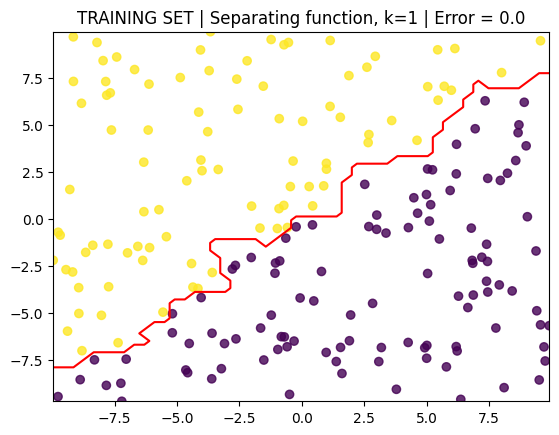

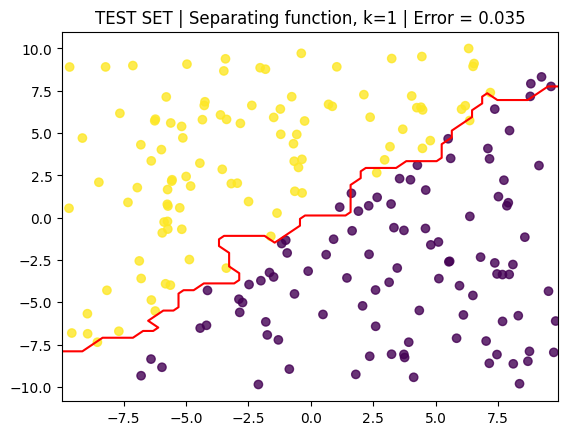

In [ ]:
### Generate training and test sets, build and evaluate the KNN classifier
n = 200
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

k = 1

####### TRAINING PHASE #######
# Generate a training set WITHOUT NOISE
Xtr, Ytr = linearBinaryClass(n,low_D,high_D,m,q)

# Evaluate the KNN classifier on the TRAINING SET
Ypredtr = kNNClassify(Xtr,Ytr,k,Xtr)

# Compute the error on the TRAINING SET
errtr = calcError(Ypredtr,Ytr)
print("With K=%d the error on the training set is " % (k), errtr)

# Visualize the separating curve
x1mesh, x2mesh, ymesh = separatingFkNN(Xtr,Ytr,k)
plt.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')

# Add points of the TRAINING SET
plt.scatter(x = Xtr[:, 0], y = Xtr[:, 1], c=Ytr, alpha=0.8)
plt.title(f'TRAINING SET | Separating function, k={k} | Error = {errtr}')#errore uguale a 0 è normale: sto cercando K=1 punti vicini a Xtr usando Xtr, sceglie se stesso come punto=> errore è zero

####### TEST PHASE #######
# Generate a test set WITHOUT NOISE
Xte, Yte = linearBinaryClass(200,low_D,high_D,m,q)

# Evaluate the KNN classifier on the TEST SET
Ypred = kNNClassify(Xtr,Ytr,k,Xte)

# Compute the error on the TEST SET
errte = calcError(Ypred,Yte)
print("With K=%d the error on the test set is " % (k), errte)

# Visualize the separating curve on a new figure
plt.figure()
plt.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')

#Add points of the TEST SET
plt.scatter(Xte[:, 0], Xte[:, 1], c=Yte, alpha=0.8)
plt.title(f'TEST SET | Separating function, k={k} | Error = {errte}')

### Assignment 4: adding noise

Keeping the parameters of the function and the number of points as in the previous assignment:

- 1.Generate a training set WITH NOISE (for instance with 10% of flipped labels)
- 2.Visualize the separating curve for the **NN** classifier
- 3.Generate a test set with the same amount of noise as the training set.
- 4.Evaluate the NN classifier on the TRAINING and on the TEST SET
- 5.Compute the obtained error on the TRAINING and on the TEST SET

- Repeat the steps from 1 to 5 with the **KNN** algorithm, setting for instance K=5

OBSERVE WHAT CHANGES...

With K=1 the error on the training test is  0.0
With K=1 the error on the test set is  0.22
With K=5 the error on the training test is  0.095
With K=5 the error on the test set is  0.5


Text(0.5, 1.0, 'TEST SET | Separating function, k=5 ')

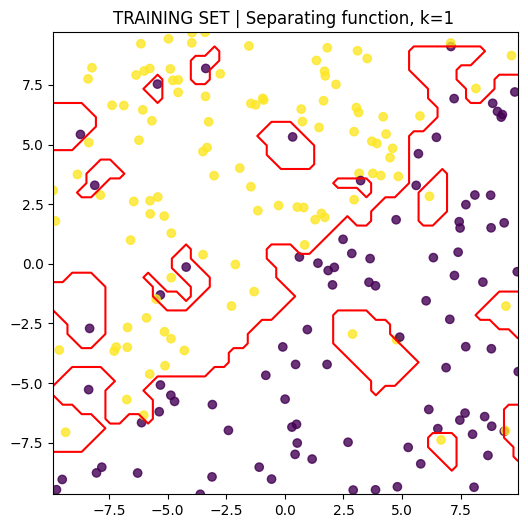

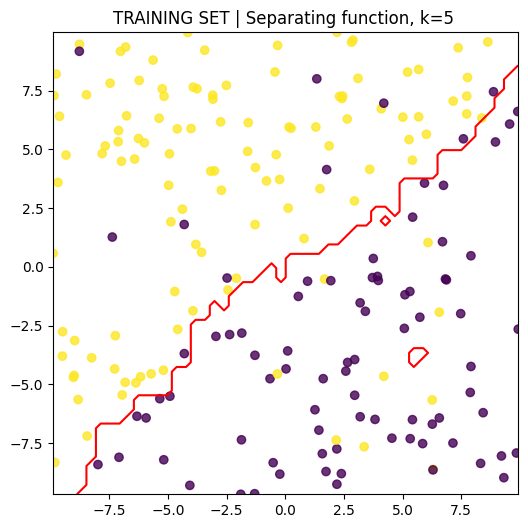

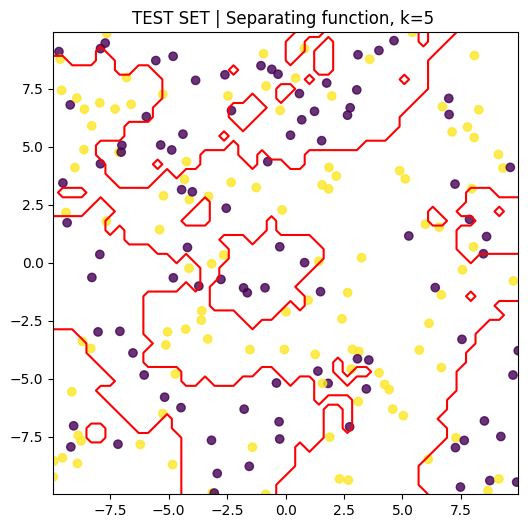

In [ ]:
#Generate Training Set
n = 200
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

k = 1
Xtr, Ytr = linearBinaryClass(n,low_D,high_D,m,q)

#Adding noise , 10% of flipped labels
Ytr_flip = flipLabels(Ytr,P=10)

#Visualize the seprating curve for the NN classifier
plt.figure(figsize=(6,6))
x1mesh, x2mesh, ymesh = separatingFkNN(Xtr,Ytr_flip,k)
plt.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')
#Adding points on the plot
plt.scatter(x = Xtr[:, 0], y = Xtr[:, 1], c=Ytr_flip, alpha=0.8)
plt.title(f'TRAINING SET | Separating function, k={k} ')

#Generate the Test Set and adding noise
Xte , Yte = linearBinaryClass(n,low_D,high_D,m,q)
Yte_flip = flipLabels(Yte,10)

#Evaluate the NN classifier for the Training Set and the Test Set
Ypredtr = kNNClassify(Xtr,Ytr_flip,k,Xtr)
Ypred = kNNClassify(Xtr,Ytr_flip,k,Xte)

#Compute the obtained error on the TRAINING and on the TEST SET
errorTR = calcError(Ypredtr,Ytr_flip)
print("With K=%d the error on the training test is " % (k), errorTR)
errorTS = calcError(Ypred,Yte_flip)
print("With K=%d the error on the test set is " % (k), errorTS)

######### K = 5 ############

#Generate Training Set

k = 5
Xtr1, Ytr1 = linearBinaryClass(n,low_D,high_D,m,q)

#Adding noise , 10% of flipped labels
Ytr_flip1 = flipLabels(Ytr1,P=10)

#Visualize the seprating curve for the NN classifier
plt.figure(figsize=(6,6))
x1mesh1, x2mesh1, ymesh1 = separatingFkNN(Xtr1,Ytr_flip1,k)
plt.contour(x1mesh1, x2mesh1, ymesh1, levels=[0], colors='red')
#Adding points on the plot
plt.scatter(x = Xtr1[:, 0], y = Xtr1[:, 1], c=Ytr_flip1, alpha=0.8)
plt.title(f'TRAINING SET | Separating function, k={k} ')

#Generate the Test Set and adding noise
Xte1 , Yte1 = linearBinaryClass(n,low_D,high_D,m,q)
Yte_flip1 = flipLabels(Yte,10)

#Evaluate the NN classifier for the Training Set and the Test Set
Ypredtr1 = kNNClassify(Xtr1,Ytr_flip1,k,Xtr1)
Ypred1 = kNNClassify(Xtr1,Ytr_flip1,k,Xte1)

#Compute the obtained error on the TRAINING and on the TEST SET
errorTR1 = calcError(Ypredtr1,Ytr_flip1)
print("With K=%d the error on the training test is " % (k), errorTR1)
errorTS1 = calcError(Ypred1,Yte_flip1)
print("With K=%d the error on the test set is " % (k), errorTS1)


# plt.figure(figsize=(6,6))
# x1mesh2, x2mesh2, ymesh2 = separatingFkNN(Xte1,Yte_flip1,k)
# plt.contour(x1mesh2, x2mesh2, ymesh2, levels=[0], colors='red')
# #Adding points on the plot
# plt.scatter(x = Xte1[:, 0], y = Xte1[:, 1], c=Yte_flip1, alpha=0.8)
# plt.title(f'TEST SET | Separating function, k={k} ')


### Assignment 5

Analyse the performance of the **KNN** with plots, considering in particular the following:



- **SCENARIO 1**: Fix the number n of points to 200, fix the amount of noise to 10%, and plot the performance of the KNN classifier on TRAINING and TEST SETS as you increase the value of K

- **SCENARIO 2**: Fix the number n of points to 200, fix the value of K to a reasonable number of neighbours, and plot the performance of the KNN classifier on TRAINING and TEST SETS as you increase the amount of noise

- **SCENARIO 3**: Fix noise and K to two reasonable values, fix the number of TEST samples to 300, and plot the performance of the KNN classifier on TRAINING and TEST SETS as you increase the number of TRAINING samples (e.g. from 30 to 300 with steps 30)

For each scenario, describe what happen

K = 1
Error Training Set =0.0
Error Test Set =0.21
K = 3
Error Training Set =0.08
Error Test Set =0.15
K = 5
Error Training Set =0.1
Error Test Set =0.15
K = 7
Error Training Set =0.115
Error Test Set =0.17
K = 9
Error Training Set =0.135
Error Test Set =0.17
K = 11
Error Training Set =0.135
Error Test Set =0.165
K = 13
Error Training Set =0.13
Error Test Set =0.155
K = 15
Error Training Set =0.125
Error Test Set =0.16
K = 17
Error Training Set =0.13
Error Test Set =0.165
K = 19
Error Training Set =0.125
Error Test Set =0.17
K = 21
Error Training Set =0.125
Error Test Set =0.165
K = 23
Error Training Set =0.12
Error Test Set =0.185
K = 25
Error Training Set =0.13
Error Test Set =0.195
K = 27
Error Training Set =0.14
Error Test Set =0.2
K = 29
Error Training Set =0.145
Error Test Set =0.205
K = 31
Error Training Set =0.15
Error Test Set =0.215
K = 33
Error Training Set =0.145
Error Test Set =0.205
K = 35
Error Training Set =0.15
Error Test Set =0.215
K = 37
Error Training Set =0.155
Err

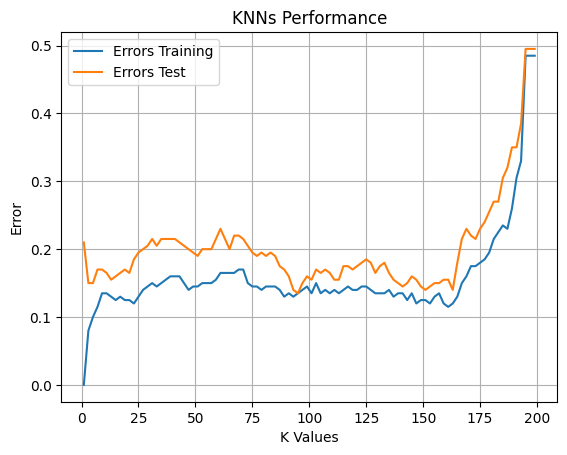

In [ ]:
#  ...SCENARIO 1...
n = 200
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

Xtr, Ytr = linearBinaryClass(n,low_D,high_D,m,q)
Ytr_flip = flipLabels(Ytr,P=10)

Xte , Yte = linearBinaryClass(n,low_D,high_D,m,q)
Yte_flip = flipLabels(Yte,10)

k_values = range(1, 200,2)

errors_TR = []
errors_TS = []

for k in k_values:
  print(f'K = {k}')
  #TRAINING SET
  Ypredtr = kNNClassify(Xtr,Ytr_flip,k,Xtr)
  errTR = calcError(Ypredtr,Ytr_flip)
  errors_TR.append(errTR)
  print(f'Error Training Set ={errTR}')

  #SET TEST
  Ypred = kNNClassify(Xtr,Ytr_flip,k,Xte)
  errTS = calcError(Ypred,Yte_flip)
  errors_TS.append(errTS)
  print(f'Error Test Set ={errTS}')

plt.plot(k_values,errors_TR,label='Errors Training')
plt.plot(k_values,errors_TS,label='Errors Test')
plt.xlabel('K Values')
plt.ylabel('Error')
plt.legend()
plt.title('KNNs Performance')
plt.grid(True)

Perc flipped labels = 5
Error Training Set =0.085
Error Test Set =0.085
Perc flipped labels = 10
Error Training Set =0.145
Error Test Set =0.14
Perc flipped labels = 15
Error Training Set =0.21
Error Test Set =0.185
Perc flipped labels = 20
Error Training Set =0.21
Error Test Set =0.25
Perc flipped labels = 25
Error Training Set =0.265
Error Test Set =0.32
Perc flipped labels = 30
Error Training Set =0.3
Error Test Set =0.355
Perc flipped labels = 35
Error Training Set =0.345
Error Test Set =0.405
Perc flipped labels = 40
Error Training Set =0.4
Error Test Set =0.415
Perc flipped labels = 45
Error Training Set =0.405
Error Test Set =0.51
Perc flipped labels = 50
Error Training Set =0.415
Error Test Set =0.475
Perc flipped labels = 55
Error Training Set =0.43
Error Test Set =0.475
Perc flipped labels = 60
Error Training Set =0.385
Error Test Set =0.49
Perc flipped labels = 65
Error Training Set =0.345
Error Test Set =0.375
Perc flipped labels = 70
Error Training Set =0.28
Error Test Set

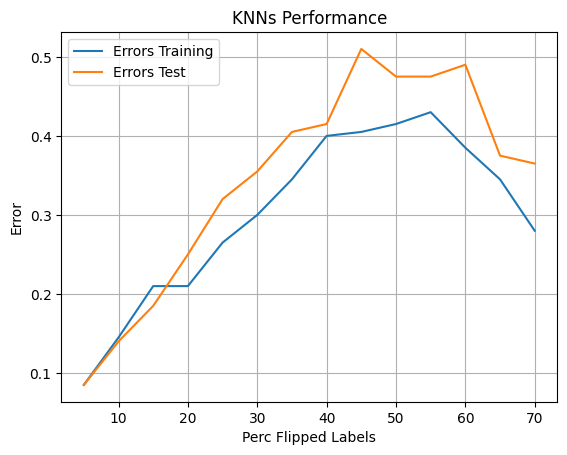

In [ ]:
# ...SCENARIO 2...

n = 200
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

Xtr, Ytr = linearBinaryClass(n,low_D,high_D,m,q)

Xte , Yte = linearBinaryClass(n,low_D,high_D,m,q)

k = 15
perc=range(5,75,5)

errors_TR = []
errors_TS = []

for P in perc:
  print(f'Perc flipped labels = {P}')
  #TRAINING SET
  Ytr_flip = flipLabels(Ytr,P)
  Ypredtr = kNNClassify(Xtr,Ytr_flip,k,Xtr)
  errors_TR.append(calcError(Ypredtr,Ytr_flip))
  print(f'Error Training Set ={calcError(Ypredtr,Ytr_flip)}')

  #SET TEST
  Yte_flip = flipLabels(Yte,P)
  Ypred = kNNClassify(Xtr,Ytr_flip,k,Xte)
  errors_TS.append(calcError(Ypred,Yte_flip))
  print(f'Error Test Set ={calcError(Ypred,Yte_flip)}')

plt.plot(perc,errors_TR,label='Errors Training')
plt.plot(perc,errors_TS,label='Errors Test')
plt.xlabel('Perc Flipped Labels')
plt.ylabel('Error')
plt.legend()
plt.title('KNNs Performance')
plt.grid(True)

Number of Training Sample = 30
Error Training Set =0.3333333333333333
Error Test Set =0.29
Number of Training Sample = 60
Error Training Set =0.13333333333333333
Error Test Set =0.22
Number of Training Sample = 90
Error Training Set =0.15555555555555556
Error Test Set =0.14333333333333334
Number of Training Sample = 120
Error Training Set =0.15
Error Test Set =0.18
Number of Training Sample = 150
Error Training Set =0.14666666666666667
Error Test Set =0.16
Number of Training Sample = 180
Error Training Set =0.15
Error Test Set =0.15
Number of Training Sample = 210
Error Training Set =0.1523809523809524
Error Test Set =0.16333333333333333
Number of Training Sample = 240
Error Training Set =0.12083333333333333
Error Test Set =0.16333333333333333
Number of Training Sample = 270
Error Training Set =0.13703703703703704
Error Test Set =0.14333333333333334
Number of Training Sample = 300
Error Training Set =0.15666666666666668
Error Test Set =0.14666666666666667


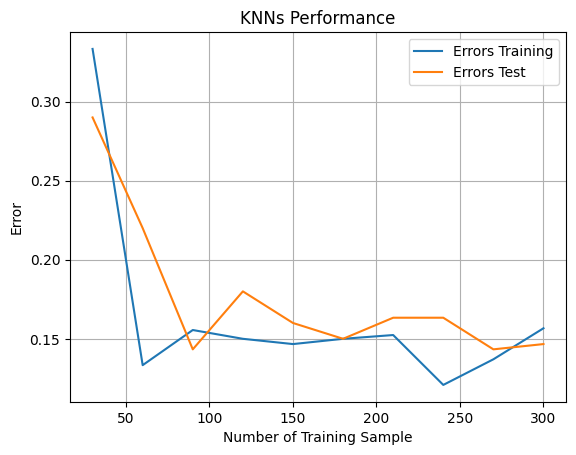

In [ ]:
# ...SCENARIO 3...

n_test = 300
n_training = [30,60,90,120,150,180,210,240,270,300]
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

k = 15
P = 12

errors_TR = []
errors_TS = []

Xte , Yte = linearBinaryClass(n_test,low_D,high_D,m,q)
Yte_flip = flipLabels(Yte,P)

for n in n_training:
  print(f'Number of Training Sample = {n}')
  #TRAINING SET
  Xtr , Ytr = linearBinaryClass(n,low_D,high_D,m,q)
  Ytr_flip = flipLabels(Ytr,P)
  Ypredtr = kNNClassify(Xtr,Ytr_flip,k,Xtr)
  errors_TR.append(calcError(Ypredtr,Ytr_flip))
  print(f'Error Training Set ={calcError(Ypredtr,Ytr_flip)}')

  #SET TEST
  Ypred = kNNClassify(Xtr,Ytr_flip,k,Xte)
  errors_TS.append(calcError(Ypred,Yte_flip))
  print(f'Error Test Set ={calcError(Ypred,Yte_flip)}')

plt.plot(n_training,errors_TR,label='Errors Training')
plt.plot(n_training,errors_TS,label='Errors Test')
plt.xlabel('Number of Training Sample')
plt.ylabel('Error')
plt.legend()
plt.title('KNNs Performance')
plt.grid(True)

## Cross-validation
In this part of the Lab, we focus on Cross-validation for model selection.

### Preliminaries: Data-loading

There are 4 datasets included with this lab, with the following properties:

  - (Training1, Test1): n=70, no noise, suggested K values are in the range 1 ... 13
  - (Training2, Test2): n=40, no noise, suggested K values are in the range 1 ... 23
  - (Training3, Test3): n=200, 20% flipped labels, suggested K values are in the range 1 ... 31
  - (Training4, Test4): n=200, 5% flipped labels, suggested K values are in the range 1 ... 19

Note that each dataset includes both a training and a test set. You **cannot use the test set to choose k**: you should assume you don't have access to the test set when doing model selection!

To load a dataset use function
`Xtr, Ytr, Xte, Yte = load_dataset(path_tr, path_te)`

Where:
- **_path\_tr_**: is the path to the file which contains the training set
- **_path\_te_**: is the path to the file which contains the test set

and it returns:
- **_Xtr_**: Inputs of training set
- **_Ytr_**: Outputs of training set
- **_Xte_**: Inputs of test set
- **_Yte_**: Outputs of test set

In [11]:
def load_dataset(path_tr, path_te):
    with open(path_tr,"rb") as f:
        [Xtr, Ytr] = pickle.load(f)
    with open(path_te,"rb") as f:
        [Xte, Yte] = pickle.load(f)
    return Xtr, Ytr, Xte, Yte

In [12]:
training_set_path = "./Material/Classification/Training4.dat"
test_set_path = "./Material/Classification/Test4.dat"
Xtr, Ytr, Xte, Yte = load_dataset(training_set_path, test_set_path)
separatingFkNN(Xtr, Ytr, 1)

(array([-9.83616723, -9.43164684, -9.02712645, -8.62260606, -8.21808567,
        -7.81356527, -7.40904488, -7.00452449, -6.6000041 , -6.19548371,
        -5.79096332, -5.38644293, -4.98192253, -4.57740214, -4.17288175,
        -3.76836136, -3.36384097, -2.95932058, -2.55480018, -2.15027979,
        -1.7457594 , -1.34123901, -0.93671862, -0.53219823, -0.12767784,
         0.27684256,  0.68136295,  1.08588334,  1.49040373,  1.89492412,
         2.29944451,  2.70396491,  3.1084853 ,  3.51300569,  3.91752608,
         4.32204647,  4.72656686,  5.13108725,  5.53560765,  5.94012804,
         6.34464843,  6.74916882,  7.15368921,  7.5582096 ,  7.96273   ,
         8.36725039,  8.77177078,  9.17629117,  9.58081156,  9.98533195]),
 array([-9.81700277, -9.41332223, -9.00964168, -8.60596113, -8.20228058,
        -7.79860004, -7.39491949, -6.99123894, -6.58755839, -6.18387785,
        -5.7801973 , -5.37651675, -4.9728362 , -4.56915566, -4.16547511,
        -3.76179456, -3.35811401, -2.95443347, -2

## Assignment 6: using the training set to choose k

Having noted that we cannot directly use the test set to find the best k, we can try to select it with the training set.
Follow these steps, and fill in the blanks in the following cells. **Comment on your findings in the notebook**.

 1. Choose a list of values for k you want to try. Check the list of suggested values for any given dataset.
 2. For each value of k do:
     1. Train a k-NN classifier with the current value of k
     2. Evaluate the error of the trained model, **on the training set**
 3. The _best_ k is the one with the lowest training error!
 4. Train a k-NN model with the chosen k, and evaluate the error **on the test set**. Is the test error similar to the training error? Does the chosen k seem like a good one?

In [ ]:
# Use dataset 4 for this task.
Xtr, Ytr, Xte, Yte = load_dataset("./Material/Classification/Training4.dat" , "./Material/Classification/Test4.dat")
k_list =  [3,4,5,6,8,9,10,11,12,13,14,15,18,20]

k_tr_errors = []
k_te_errors = []

for current_k in k_list:
    # TODO: train a KNN model, calculate the error on the training set.
    Ypredtr = kNNClassify(Xtr,Ytr,current_k,Xtr)
    #Ypred = kNNClassify(Xtr,Ytr,current_k,Xte)
    current_tr_err = calcError(Ypredtr,Ytr)
    k_tr_errors.append(current_tr_err)
    #current_te_err = calcError(Ypred,Yte)
    #k_te_errors.append(current_te_err)

# TODO: pick the best value of k using k_list and k_tr_errors.
#is the one with the lowest training errors, use argsort in the vector k_tr_errors for obtaine the indx with lowest error that if i use in the k_list give me the best_k
order_idx_k_tr_error = np.argsort(k_tr_errors)
best_k = k_list[order_idx_k_tr_error[0]] #ritorna 1 se nella k_list è presente, in base a quanto detto prima infatti ha errore 0 nel triaing set . errore zero pure con 2 in lista
#dopo c'è 4 con errore 5% e poi 8 con lo stesso errore, poi 10 sempre con 5% errore,poi 6 con 5,5%

print(f"The best k chosen with the training-set is: {best_k}\n"
      f"with training error {np.min(k_tr_errors)*100:.2f}%")

The best k chosen with the training-set is: 4
with training error 5.00%


In [ ]:
# Evaluate the model with the best k on the test set now
te_err = calcError(kNNClassify(Xtr,Ytr,best_k,Xte),Yte)
print(f"The test error with the best k ({best_k}) is: {te_err*100:.2f}%") #without k=1 there is an higher error than the training one's but is not so rilevant , the error now is 7%

The test error with the best k (4) is: 10.50%


Text(0, 0.5, 'test error')

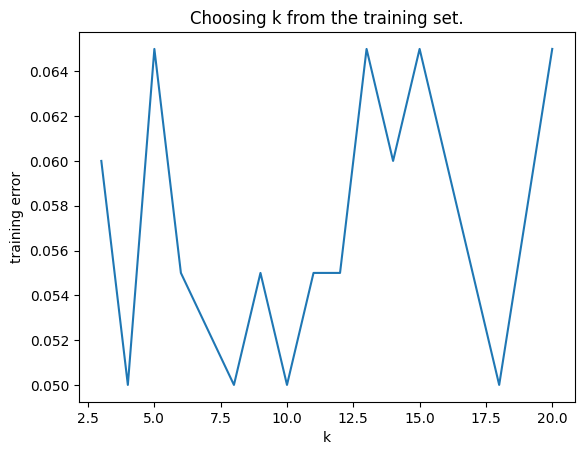

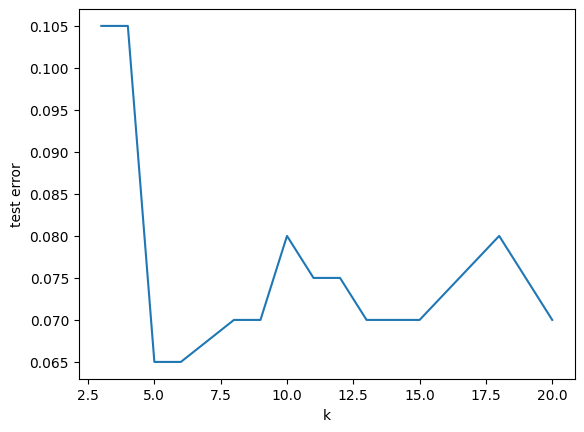

In [ ]:
# Plot how the training error changes with k
fig, ax = plt.subplots()
ax.plot(k_list, k_tr_errors)
ax.set_xlabel("k")
ax.set_ylabel("training error")
ax.set_title("Choosing k from the training set.")

# fig, ax = plt.subplots()
# ax.plot(k_list, k_te_errors)
# ax.set_xlabel("k")
# ax.set_ylabel("test error")


#### Observations:

- The k chosen was k=1 because since we are training and testing on the training data, the closest points are themselves and the error is zero.

- When we apply this training with k=1 on the test data, this performs poorly (12% of error). So the k is a very bad choice, it is overfitting the training data.

What happens for *very high* values of k (e.g. k=150 or 200)?

What happens if we evaluate different values of k on the TEST set?



## Assignment 7: K-Fold cross validation

The training error does not provide good estimates of the test error. So using the training error for model selection means you will select a k which is not good for the test set.

A simple way, which is much better than the training error, to estimate the test error is to use a **k-fold cross validation**. In K-Fold cross validation, the data are split into K parts of approximately equal size, and K different models are trained each time leaving out one of the parts of data. Then the estimate for the test error is the mean of the error of the K different models.

In this task you will implement K-Fold CV, and run the same analysis as in the previous cell.

In [9]:
def KFoldCVkNN(Xtr, Ytr, num_folds, k_list):
    """Run K-Fold CV for the kNN model

    Parameters:
    -----------
     - Xtr : np.array
         the full training set data
     - Ytr : np.array
         the full training set labels
     - num_folds : int
         the number of folds
     - k_list : List[int]
         the values of k (for k-NN) to try.

    Returns:
    --------
     - best_k : int
         The value of k (in k_list) which obtains the best average validation error
     - best_k_idx : int
         The index of the best_k element in k_list
     - tr_err_mean : np.array
         A 1D array of the same length as k_list, with the average training error for each tested k.
     - tr_err_std : np.array
         A 1D array of the same length as k_list, with the standard deviation
         of the training error for each tested k.
     - val_err_mean : np.array
         A 1D array of the same length as k_list, with the average validation error for each tested k.
     - val_err_std : np.array
         A 1D array of the same length as k_list, with the standard deviation
         of the validation error for each tested k.
    """
    rnd_state = np.random.RandomState()
    # Ensures that k_list is a numpy array
    k_list = np.array(k_list)
    num_k = len(k_list)

    n_tot = Xtr.shape[0]
    n_val = n_tot // num_folds

    # We want to compute 1 error for each `k` and each fold
    tr_errors = np.zeros((num_k, num_folds))
    val_errors = np.zeros((num_k, num_folds))

    # `split_idx`: a list of arrays, each containing the validation indices for 1 fold
    rand_idx = rnd_state.choice(n_tot, size=n_tot, replace=False)
    split_idx = np.array_split(rand_idx, num_folds)

    for fold_idx in range(num_folds):
        # Set the indices in boolean mask for all validation samples to `True`
        val_mask = np.zeros(n_tot, dtype=bool)
        val_mask[split_idx[fold_idx]] = True
        # Split training set in training part and validation part
        # Hint: you can use boolean mask as index vector to split Xtr and Ytr
        x_train = Xtr[~val_mask]
        y_train = Ytr[~val_mask]
        x_val = Xtr[val_mask]
        y_val = Ytr[val_mask]

        for k_idx, current_k in enumerate(k_list):
            # Compute the training error of the kNN classifier for the given value of k
            Ypredtr = kNNClassify(x_train,y_train,current_k,x_train)
            tr_errors[k_idx, fold_idx] = calcError(Ypredtr,y_train)
            # Compute the validation error of the kNN classifier for the given value of k
            Ypredval = kNNClassify(x_train,y_train,current_k,x_val)
            val_errors[k_idx, fold_idx] = calcError(Ypredval,y_val)

    # Calculate error statistics along the repetitions:
    # 1) mean training error, training error standard deviation
    tr_err_mean = np.mean(tr_errors,axis=1)
    tr_err_std = np.std(tr_errors,axis=1)
    # 2) mean validation error, validation error standard deviation
    val_err_mean = np.mean(val_errors,axis=1)
    val_err_std = np.std(val_errors,axis=1)
    # 3) best k (k which minimize mean validation error) and index of best k in k_list
    best_k_idx = np.argmin(val_err_mean)
    best_k = k_list[best_k_idx]

    return best_k, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std

The best K is :13


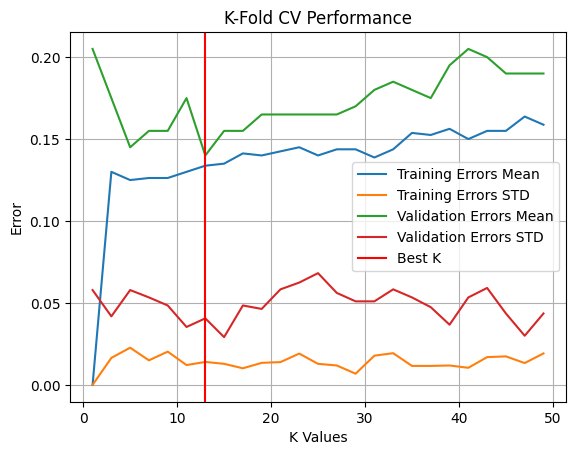

In [15]:
# Perform the same analysis of Assignment 5 using K-Fold CV
# INSERT YOUR CODE HERE

n = 200
D = 2

m = 0.9
q = 0.0

low_D = -10
high_D = 10

Xtr, Ytr = linearBinaryClass(n,low_D,high_D,m,q)
Ytr_flip = flipLabels(Ytr,P=10)

Xte , Yte = linearBinaryClass(n,low_D,high_D,m,q)
Yte_flip = flipLabels(Yte,10)

k_values = range(1,50,2)
num_folds = 5

best_k, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std = KFoldCVkNN(Xtr,Ytr_flip,num_folds,k_values)
print(f'The best K is :{best_k}')

plt.plot(k_values,tr_err_mean,label='Training Errors Mean')
plt.plot(k_values,tr_err_std,label='Training Errors STD')
plt.plot(k_values,val_err_mean,label='Validation Errors Mean')
plt.plot(k_values,val_err_std,label='Validation Errors STD')
plt.axvline(x=best_k,color='red',label='Best K')
plt.xlabel('K Values')
plt.ylabel('Error')
plt.legend()
plt.title('K-Fold CV Performance')
plt.grid(True)

In [ ]:
# **ADVANCED**
#
# labeling, specifically error in fractions vs. percentage
#
# fig, ax = plt.subplots()
# ax.plot(k_list, val_err_mean, label="Validation")
#
# Be careful about +/- val_err_std and, for example, +/- 3*val_err_std

# ax.fill_between(k_list, val_err_mean - val_err_std, val_err_mean + val_err_std, alpha=0.2)
# ax.plot(k_list, tr_err_mean, label="Training")
# ax.fill_between(k_list, tr_err_mean - tr_err_std, tr_err_mean + tr_err_std, alpha=0.2)
# ax.set_title(f"{num_folds}-Fold CV")
# ax.set_ylabel("Error, fraction")
# ax.set_xlabel("$k$")
# ax.legend();

Does the best k (and the test error) change w.r.t. assignment 5?

In [ ]:
# **ADVANCED**
#
# In the definition of KFoldCVkNN
# rng = np.random.default_rng()
# can be used instead of
# rnd_state = np.random.RandomState()

## Assignment 8: Cross validation and Noise in K-NN

In this final task we consider the effect of noise on the best k (chosen with k-fold CV).

We will use dataset 3 which has high noise (20%), and dataset 4 which has low noise (5%).

You will have to do the following:
 1. Use k-fold CV to find the best k for datasets 3 and 4.
 2. Compare the obtained values of k, with the actual best k on the test error of the two datasets. This should be a sanity check: if the errors on k-fold CV and on the test set are very different, something may be wrong with your code.
 3. Comment on how noise affects the best k: does a more noisy dataset need a higher or a lower k, and why? It may be useful to plot the separating function (using the `separatingFkNN` function) of k-NN with the best k for the two datasets.

In [ ]:
num_folds = 5
k_list = range(1, 19, 2)

**Dataset 3 (high noise)**

In [ ]:
# Load dataset 3 (high noise)
Xtr, Ytr, Xte, Yte = load_dataset(
    "./Material/Classification/Training3.dat", "./Material/Classification/Test3.dat")

In [ ]:
#TODO: Find the best k on the test set of dataset
best_k_train, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std = KFoldCVkNN(Xtr,Ytr,num_folds,k_list)
print(f'The best K in Training Set is :{best_k_train}')

#Best k on test set
errors_test = np.zeros(len(k_list)) #inizializzo a un vettore di zeri

for k_idx, current_k in enumerate(k_list):
    Ypred_test = kNNClassify(Xtr,Ytr,current_k,Xte)
    errors_test[k_idx] = calcError(Ypred_test,Yte)

best_k_test_idx = np.argmin(errors_test)
best_k_test = k_list[best_k_test_idx]
print(f'The best K in Test Set is :{best_k_test}')

The best K in Training Set is :7
The best K in Test Set is :11


In [ ]:
#TODO: Compute the test error
te_err = calcError(kNNClassify(Xtr,Ytr,best_k_test,Xte),Yte)
tr_err = calcError(kNNClassify(Xtr,Ytr,best_k_train,Xtr),Ytr)

print(f'The train error is :{tr_err*100:.2f}%')
print(f'The test error is :{te_err*100:.2f}%')

The train error is :21.50%
The test error is :20.00%


Text(0.5, 1.0, 'TRAINING SET | Separating function, k=7')

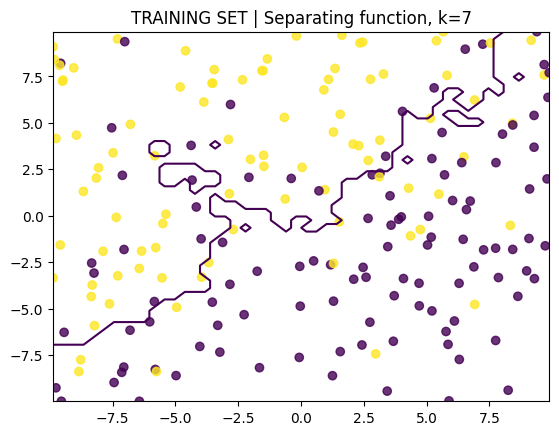

In [ ]:
#TODO: Plot separatingFkNN on the TRAINING SET
x1mesh , x2mesh , ymesh = separatingFkNN(Xtr,Ytr,best_k_train)
plt.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')

plt.scatter(x = Xtr[:, 0], y = Xtr[:, 1], c=Ytr, alpha=0.8)
plt.title(f'TRAINING SET | Separating function, k={best_k_train}')


**Dataset 4 (low noise)**

In [ ]:
# Load dataset 4 (low noise)
Xtr, Ytr, Xte, Yte = load_dataset(
    "./Material/Classification/Training4.dat", "./Material/Classification/Test4.dat")

In [ ]:
#TODO: Find the best k on the test set of dataset
#Using Cross Validation per ottenere il migliore k
best_k_train, best_k_idx, tr_err_mean, tr_err_std, val_err_mean, val_err_std = KFoldCVkNN(Xtr,Ytr,num_folds,k_list)
print(f'The best K in Training Set is :{best_k_train}')

#Best k on test set
errors_test = np.zeros(len(k_list)) #inizializzo a un vettore di zeri

for k_idx, current_k in enumerate(k_list):
    Ypred_test = kNNClassify(Xtr,Ytr,current_k,Xte)
    errors_test[k_idx] = calcError(Ypred_test,Yte)

best_k_test_idx = np.argmin(errors_test)
best_k_test = k_list[best_k_test_idx]
print(f'The best K in Test Set is :{best_k_test}')

The best K in Training Set is :15
The best K in Test Set is :5


In [ ]:
#TODO: Compute the test error
te_err = calcError(kNNClassify(Xtr,Ytr,best_k_test,Xte),Yte)
tr_err = calcError(kNNClassify(Xtr,Ytr,best_k_train,Xtr),Ytr)

print(f'The train error is :{tr_err*100:.2f}%')
print(f'The test error is :{te_err*100:.2f}%')

The train error is :6.50%
The test error is :6.50%


Text(0.5, 1.0, 'TRAINING SET | Separating function, k=15')

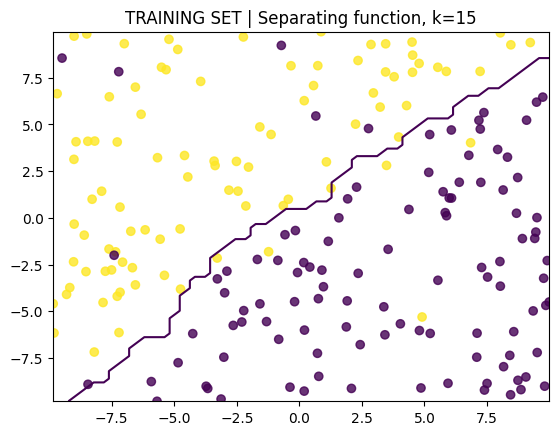

In [ ]:
#TODO: Plot separatingFkNN on the TRAINING SET
x1mesh , x2mesh , ymesh = separatingFkNN(Xtr,Ytr,best_k_train)
plt.contour(x1mesh, x2mesh, ymesh, levels=[0], colors='red')

plt.scatter(x = Xtr[:, 0], y = Xtr[:, 1], c=Ytr, alpha=0.8)
plt.title(f'TRAINING SET | Separating function, k={best_k_train}')

How does noise affect the best k?